In [1]:
import pandas as pd

In [2]:
# Hit groups are provided by Conny
# Compund clusters are provided by Yurii (How?)

# compound ID
# hit group number
# structure cluster number
# deltaSpSh
# deltaTm

In [3]:
df = pd.read_csv("data/PO_processed_with_p-val_26jul.csv")[['ID', 'delta_Thermal_Shift', 'delta_Spectral_Shift', 'Protein']]
df = df.loc[~ df['ID'].isin(['BH4', 'UCR243', 'UCR102'])].copy()
df['id_prot'] = [f"{i}_{j.split('-')[1]}" for i, j in zip(df['ID'], df['Protein'])]
df

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_35303/3632513450.py:1: DtypeWarning: Columns (24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/PO_processed_with_p-val_26jul.csv")[['ID', 'delta_Thermal_Shift', 'delta_Spectral_Shift', 'Protein']]


,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot
2,CSCS00104537142,0.0000,0.058468,PAH-WT,CSCS00104537142_WT
3,CSCS00133135693,0.0000,0.046473,PAH-WT,CSCS00133135693_WT
4,CSCS00093835758,0.1803,0.043245,PAH-WT,CSCS00093835758_WT
5,CSCS00133112516,0.1803,0.104088,PAH-WT,CSCS00133112516_WT
6,CSCS00133028662,-0.3608,0.073183,PAH-WT,CSCS00133028662_WT
...,...,...,...,...,...
142131,CSCS00026514704,0.0902,0.013302,PAH-I65T,CSCS00026514704_I65T
142132,CSCS00106139536,0.0902,0.075777,PAH-I65T,CSCS00106139536_I65T
142133,CSCS00028326356,-0.2705,0.016714,PAH-I65T,CSCS00028326356_I65T
142134,CSCS00103366980,0.0902,-0.022446,PAH-I65T,CSCS00103366980_I65T


In [4]:
df_hit_group = pd.read_excel("Hit_Groups_clear.xlsx")
df_hit_group

,WT SNN,I65T SNN,WT WNN,I65T WNN,WT SSN,I65T SSN,WT WWN,I65T WWN,WT WSN,I65T WSN,...,WT SNS,WT WNW,I65T WNW,WT NSN,I65T NSN,WT NWN,I65T NWN,WT NNS,WT NNW,I65T NNW
0,CSCS00102900928,CSCS00027417060,CSCS00133112516,CSCS00026246874,CSCS00060628778,CSCS00133070215,CSCS00133044388,CSCS00025932193,CSCS00058439641,CSCS00026891577,...,CSCS00133109732,CSCS00133028662,CSCS00026026211,CSCS00027602153,CSCS00133087908,CSCS00133114385,CSCS00026383546,CSCS00076457713,CSCS00091889232,CSCS00026062610
1,CSCS00028048484,CSCS00025849069,CSCS00102894933,CSCS00026816510,CSCS00058478956,CSCS00046129028,CSCS00027220170,CSCS00026104743,CSCS00133059449,CSCS00028205893,...,CSCS00026805338,CSCS00133087567,CSCS00026575066,CSCS00133137326,CSCS00027300921,CSCS00102900170,CSCS00026816145,CSCS00027626108,CSCS00133066869,CSCS00027095748
2,CSCS00027042542,CSCS00025888016,CSCS00133104373,CSCS00027148452,CSCS00058968459,CSCS00025932475,CSCS00026432139,CSCS00028050801,CSCS00116285367,CSCS00027242429,...,CSCS00027236166,CSCS00133099652,CSCS00133146646,CSCS00027517672,CSCS00026636495,CSCS00133061501,CSCS00028147264,CSCS00027080754,CSCS00027148854,CSCS00102891969
3,CSCS00027439089,CSCS00028229109,CSCS00116284404,CSCS00027507678,CSCS00025853500,CSCS00025950759,CSCS00027316425,CSCS00102891055,CSCS00058923669,CSCS00027353720,...,CSCS00028037841,CSCS00133044588,CSCS00028141865,CSCS00133045870,CSCS00133122494,CSCS00027867800,CSCS00026476457,CSCS00133086337,CSCS00028307373,CSCS00027507368
4,CSCS00027489084,CSCS00025976476,CSCS00133051902,CSCS00026334773,CSCS00028077718,CSCS00027443381,CSCS00027916467,CSCS00027220226,CSCS00027323580,CSCS00026961024,...,CSCS00028185967,CSCS00133043343,CSCS00027203025,CSCS00027663337,CSCS00025880774,CSCS00133144638,CSCS00028201743,CSCS00067125439,CSCS00133146767,CSCS00026530504
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14205,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CSCS00027265738,NaN
14206,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CSCS00057900114,NaN
14207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CSCS00102904419,NaN
14208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CSCS00027744926,NaN


In [5]:
df_hit_group_reshaped_list = []

for col in df_hit_group.columns:
    ids = df_hit_group[col]
    ids = list(ids.dropna())
    df_tmp = pd.DataFrame(
        {
            'ID' : ids,
            'hit group' : [col] * len(ids)
        }
    )
    df_hit_group_reshaped_list.append(df_tmp)

df_hit_group_reshaped = pd.concat(df_hit_group_reshaped_list)
df_hit_group_reshaped['id_prot'] = [f"{i}_{j.split(' ')[0]}" for i, j in zip(df_hit_group_reshaped['ID'], df_hit_group_reshaped['hit group'])]
df_hit_group_reshaped

,ID,hit group,id_prot
0,CSCS00102900928,WT SNN,CSCS00102900928_WT
1,CSCS00028048484,WT SNN,CSCS00028048484_WT
2,CSCS00027042542,WT SNN,CSCS00027042542_WT
3,CSCS00027439089,WT SNN,CSCS00027439089_WT
4,CSCS00027489084,WT SNN,CSCS00027489084_WT
...,...,...,...
12522,CSCS00027715863,I65T NNW,CSCS00027715863_I65T
12523,CSCS00026024823,I65T NNW,CSCS00026024823_I65T
12524,CSCS00073481239,I65T NNW,CSCS00073481239_I65T
12525,CSCS00026212920,I65T NNW,CSCS00026212920_I65T


In [6]:
df_cluster = pd.read_excel("Hit_clusters_Yurii.xlsx", skiprows=1)
df_cluster = df_cluster[['Catalog_ID', 'Cluster No 2']]
df_cluster.columns = ['ID', 'cluster_id']
df_cluster

,ID,cluster_id
0,CSCS00028098172,4153
1,CSCS00027240445,3452
2,CSCS00027203935,3212
3,CSCS00027398006,3677
4,CSCS00026214966,1712
...,...,...
20400,CSCS00011408384,3717
20401,CSCS00011078444,3895
20402,CSCS00028092148,3923
20403,CSCS00020597494,3624


In [7]:
df_merged = pd.merge(df, df_hit_group_reshaped, on='id_prot', how='inner', suffixes=('', '_'))
df_merged = pd.merge(df_merged, df_cluster, on='ID', how='left')
df_merged['protein'] = [i.split(' ')[0] for i in df_merged['hit group']]
df_merged['hit_group'] = [i.split(' ')[1] for i in df_merged['hit group']]
df_merged = df_merged.drop('hit group', axis=1)
df_merged['delta_TS_greater_2'] = df_merged['delta_Thermal_Shift'] > 2
df_merged

,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_id,protein,hit_group,delta_TS_greater_2
0,CSCS00133112516,0.1803,0.104088,PAH-WT,CSCS00133112516_WT,CSCS00133112516,NaN,WT,WNN,False
1,CSCS00133028662,-0.3608,0.073183,PAH-WT,CSCS00133028662_WT,CSCS00133028662,3672.0,WT,WNW,False
2,CSCS00102894933,-0.0902,0.074976,PAH-WT,CSCS00102894933_WT,CSCS00102894933,NaN,WT,WNN,False
3,CSCS00133087567,-0.3608,0.121360,PAH-WT,CSCS00133087567_WT,CSCS00133087567,44.0,WT,WNW,False
4,CSCS00091889232,-0.4509,0.008994,PAH-WT,CSCS00091889232_WT,CSCS00091889232,3880.0,WT,NNW,False
...,...,...,...,...,...,...,...,...,...,...
73488,CSCS00026206223,0.3607,0.006990,PAH-I65T,CSCS00026206223_I65T,CSCS00026206223,NaN,I65T,NWN,False
73489,CSCS00026213034,0.3607,0.049883,PAH-I65T,CSCS00026213034_I65T,CSCS00026213034,1422.0,I65T,NWN,False
73490,CSCS00133070580,0.3607,0.024471,PAH-I65T,CSCS00133070580_I65T,CSCS00133070580,NaN,I65T,NWN,False
73491,CSCS00026188135,0.4509,0.020881,PAH-I65T,CSCS00026188135_I65T,CSCS00026188135,NaN,I65T,NWN,False


In [8]:
df_merged.to_csv("Hit_grouped_final.csv")
df_merged.to_excel("Hit_grouped_final.xlsx")

In [66]:
top_clusters = [3068, 3837, 3534]
df_merged['cluster_number'].value_counts().sort_values()

cluster_number
574.0       1
4077.0      1
1721.0      1
280.0       1
599.0       1
         ... 
3452.0     98
3524.0    104
3534.0    111
3837.0    121
3068.0    125
Name: count, Length: 4156, dtype: int64

In [80]:
# Get ligands in top clusters
df_merged_wt = df_merged.loc[df_merged['Protein'] == 'PAH-WT']
df_merged_mut = df_merged.loc[df_merged['Protein'] == 'PAH-I65T']

for c in top_clusters:
    print(f"cluster number: {c}")
    print(f"total number : {(df_merged['cluster_number'] == c).sum()}")
    print(f"total number : {(df_merged['cluster_number'] == c).sum()}")
    print('')
    print('WT')
    print(f"total number WT : {(df_merged_wt['cluster_number'] == c).sum()}")
    count_table = df_merged_wt.loc[df_merged_wt['cluster_number'] == c, 'hit_group'].value_counts()
    print(count_table)
    (df_merged_wt['cluster_number'] == c).to_excel(f"Hit_grouped_WT_cluster_{c}.xlsx")
    print('')
    print('I65T')
    print(f"total number I65T : {(df_merged_mut['cluster_number'] == c).sum()}")
    count_table = df_merged_mut.loc[df_merged_mut['cluster_number'] == c, 'hit_group'].value_counts()
    print(count_table)
    (df_merged_wt['cluster_number'] == c).to_excel(f"Hit_grouped_I65T_cluster_{c}.xlsx")
    print("----------")

cluster number: 3068
total number : 125
total number : 125

WT
total number WT : 69
hit_group
NSN        24
S/WS/WN    18
WSN        13
NWN         5
WWN         4
WNN         2
WNW         1
SNS         1
SSN         1
Name: count, dtype: int64

I65T
total number I65T : 56
hit_group
S/WS/WN    17
NSN        15
WSN        11
WWN         5
NWN         4
SNN         2
SSN         1
WNN         1
Name: count, dtype: int64
----------
cluster number: 3837
total number : 121
total number : 121

WT
total number WT : 65
hit_group
NSN        24
S/WS/WN    17
WSN        15
NWN         4
NNW         2
WWN         1
WNN         1
SSN         1
Name: count, dtype: int64

I65T
total number I65T : 56
hit_group
NSN        18
S/WS/WN    17
WSN        14
SSN         2
NWN         2
WNW         1
WNN         1
WWN         1
Name: count, dtype: int64
----------
cluster number: 3534
total number : 111
total number : 111

WT
total number WT : 61
hit_group
NNW        21
WNW        11
WNN         7
S/WS/WN   

In [ ]:
# Separate per group

In [30]:
c1 = df_merged[df_merged['protein'] == 'WT'].groupby('hit_group').count()['ID'].reindex(hit_groups, fill_value=0)
c2 = df_merged[df_merged['protein'] == 'I65T'].groupby('hit_group').count()['ID'].reindex(hit_groups, fill_value=0)
df_count = pd.DataFrame({
    'WT'   : c1,
    'I65T' : c2,
    'both' : 0,
    'WT_exc' : 0,
    'I65T_exc' : 0
})
# df_count

,WT,I65T,both,WT_exc,I65T_exc
hit_group,,,,,
WNN,8621,7836,0,0,0
WNW,4291,3634,0,0,0
NNW,14210,12527,0,0,0
NSN,2054,1734,0,0,0
NNS,1254,0,0,0,0
NWN,2118,3286,0,0,0
WSN,1204,1315,0,0,0
S/WS/WN,2221,3066,0,0,0
WWN,757,1368,0,0,0


In [61]:
# intersection
for i in hit_groups:
    id_wt = set(df_merged.loc[(df_merged['protein'] == 'WT') & (df_merged['hit_group'] == i), 'ID'])
    id_i65t = set(df_merged.loc[(df_merged['protein'] == 'I65T') & (df_merged['hit_group'] == i), 'ID'])
    df_count.loc[i, 'both'] = len(id_wt.intersection(id_i65t))
    df_count.loc[i, 'WT_exc'] = len(id_wt - id_i65t)
    df_count.loc[i, 'I65T_exc'] = len(id_i65t - id_wt)

    if i == 'S/WS/WN':
        ids = {
            'both'    : id_wt.intersection(id_i65t),
            'WT_exc'   : id_wt - id_i65t,
            'I65T_exc' : id_i65t - id_wt
        }
        df_merged.loc[((df_merged['ID'].isin(ids['both'])) & (df_merged['hit_group'] == i))].reset_index().to_excel(f'S-WS-WN_both.xlsx')
        df_merged.loc[((df_merged['ID'].isin(ids['WT_exc'])) & (df_merged['hit_group'] == i) & (df_merged['protein'] == 'WT'))].reset_index().to_excel(f'S-WS-WN_WT_exc.xlsx')
        df_merged.loc[((df_merged['ID'].isin(ids['I65T_exc'])) & (df_merged['hit_group'] == i) & (df_merged['protein'] == 'I65T'))].reset_index().to_excel(f'S-WS-WN_I65T_exc.xlsx')

df_count

,WT,I65T,both,WT_exc,I65T_exc
hit_group,,,,,
WNN,8621,7836,1630,6991,6206
WNW,4291,3634,623,3668,3011
NNW,14210,12527,3590,10620,8937
NSN,2054,1734,842,1212,892
NNS,1254,0,0,1254,0
NWN,2118,3286,415,1703,2871
WSN,1204,1315,419,785,896
S/WS/WN,2221,3066,970,1251,2096
WWN,757,1368,90,667,1278


In [58]:
df_merged.loc[((df_merged['ID'].isin(ids['both'])) & (df_merged['hit_group'] == 'S/WS/WN'))]

,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_number,protein,hit_group,delta_TS_greater_2
2334,CSCS00028205893,2.0742,0.103874,PAH-WT,CSCS00028205893_WT,CSCS00028205893,1612.0,WT,S/WS/WN,True
2336,CSCS00027242429,0.6313,0.166264,PAH-WT,CSCS00027242429_WT,CSCS00027242429,2860.0,WT,S/WS/WN,False
2373,CSCS00068284259,0.3607,-0.103026,PAH-WT,CSCS00068284259_WT,CSCS00068284259,2288.0,WT,S/WS/WN,False
2390,CSCS00026155739,0.9920,-0.098120,PAH-WT,CSCS00026155739_WT,CSCS00026155739,4213.0,WT,S/WS/WN,False
2435,CSCS00027242424,0.9920,0.120717,PAH-WT,CSCS00027242424_WT,CSCS00027242424,1313.0,WT,S/WS/WN,False
...,...,...,...,...,...,...,...,...,...,...
72924,CSCS00026732677,0.9920,-0.080133,PAH-I65T,CSCS00026732677_I65T,CSCS00026732677,921.0,I65T,S/WS/WN,False
72930,CSCS00027607533,1.2625,0.158251,PAH-I65T,CSCS00027607533_I65T,CSCS00027607533,2701.0,I65T,S/WS/WN,False
73158,CSCS00026030892,5.4109,-0.121553,PAH-I65T,CSCS00026030892_I65T,CSCS00026030892,4019.0,I65T,S/WS/WN,True
73174,CSCS00101826481,3.7876,-0.124172,PAH-I65T,CSCS00101826481_I65T,CSCS00101826481,2461.0,I65T,S/WS/WN,True


In [93]:
# First unique for cluster and then Separate per group 

In [102]:
i = 'S/WS/WN'

id_wt = set(df_merged.loc[(df_merged['protein'] == 'WT') & (df_merged['hit_group'] == i), 'ID'])
id_i65t = set(df_merged.loc[(df_merged['protein'] == 'I65T') & (df_merged['hit_group'] == i), 'ID'])

ids = {
            'both'    : id_wt.intersection(id_i65t),
            'WT_exc'   : id_wt - id_i65t,
            'I65T_exc' : id_i65t - id_wt
        }

df_new = df_merged.loc[((df_merged['ID'].isin(ids['both'])) & (df_merged['hit_group'] == i))].reset_index()
df_new = df_new.drop_duplicates(subset='cluster_number', keep='first').reset_index()
df_new['delta_TS_greater_2'].value_counts().sort_values()

delta_TS_greater_2
True      96
False    549
Name: count, dtype: int64

,level_0,index,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_number,protein,hit_group,delta_TS_greater_2
0,0,2334,CSCS00028205893,2.0742,0.103874,PAH-WT,CSCS00028205893_WT,CSCS00028205893,1612.0,WT,S/WS/WN,True
5,5,2457,CSCS00133070215,2.3447,0.157605,PAH-WT,CSCS00133070215_WT,CSCS00133070215,1867.0,WT,S/WS/WN,True
15,16,2953,CSCS00025950759,3.2465,0.185692,PAH-WT,CSCS00025950759_WT,CSCS00025950759,2194.0,WT,S/WS/WN,True
16,17,5644,CSCS00027319139,2.8407,0.074163,PAH-WT,CSCS00027319139_WT,CSCS00027319139,2784.0,WT,S/WS/WN,True
25,27,6032,CSCS00027049410,2.7956,0.154890,PAH-WT,CSCS00027049410_WT,CSCS00027049410,3599.0,WT,S/WS/WN,True
...,...,...,...,...,...,...,...,...,...,...,...,...
630,1688,64217,CSCS00059917190,2.7055,0.081566,PAH-WT,CSCS00059917190_WT,CSCS00059917190,212.0,WT,S/WS/WN,True
632,1690,64277,CSCS00028117226,2.3447,-0.076788,PAH-WT,CSCS00028117226_WT,CSCS00028117226,3131.0,WT,S/WS/WN,True
635,1695,64503,CSCS00028229003,2.7956,0.191023,PAH-WT,CSCS00028229003_WT,CSCS00028229003,892.0,WT,S/WS/WN,True
639,1702,64733,CSCS00133027058,3.3818,-0.210181,PAH-WT,CSCS00133027058_WT,CSCS00133027058,3707.0,WT,S/WS/WN,True


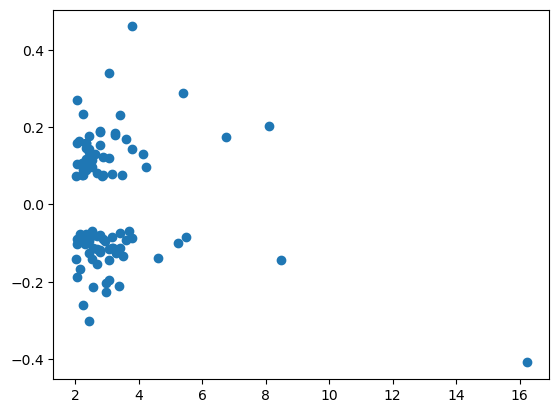

In [123]:
# add all true to df_final
df_new_true = df_new.loc[df_new['delta_TS_greater_2']]
df_final = df_new_true
plt.scatter(df_new_true['delta_Thermal_Shift'], df_new_true['delta_Spectral_Shift'])
df_final

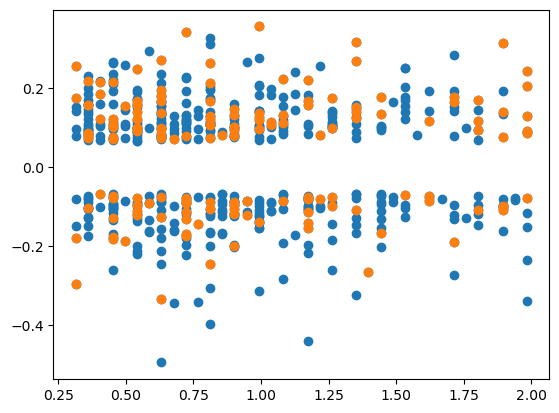

In [124]:
df_new_false = df_new.loc[~df_new['delta_TS_greater_2']]
df_subset = df_new_false.sample(n=154, random_state=100)
plt.scatter(df_new_false['delta_Thermal_Shift'], df_new_false['delta_Spectral_Shift'])
plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

In [125]:
df_final = pd.concat([df_final, df_subset])
df_final

,level_0,index,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_number,protein,hit_group,delta_TS_greater_2
0,0,2334,CSCS00028205893,2.0742,0.103874,PAH-WT,CSCS00028205893_WT,CSCS00028205893,1612.0,WT,S/WS/WN,True
5,5,2457,CSCS00133070215,2.3447,0.157605,PAH-WT,CSCS00133070215_WT,CSCS00133070215,1867.0,WT,S/WS/WN,True
15,16,2953,CSCS00025950759,3.2465,0.185692,PAH-WT,CSCS00025950759_WT,CSCS00025950759,2194.0,WT,S/WS/WN,True
16,17,5644,CSCS00027319139,2.8407,0.074163,PAH-WT,CSCS00027319139_WT,CSCS00027319139,2784.0,WT,S/WS/WN,True
25,27,6032,CSCS00027049410,2.7956,0.154890,PAH-WT,CSCS00027049410_WT,CSCS00027049410,3599.0,WT,S/WS/WN,True
...,...,...,...,...,...,...,...,...,...,...,...,...
239,300,15602,CSCS00025872170,0.9920,0.356758,PAH-WT,CSCS00025872170_WT,CSCS00025872170,2819.0,WT,S/WS/WN,False
446,602,26177,CSCS00026389431,0.5411,0.091054,PAH-WT,CSCS00026389431_WT,CSCS00026389431,3496.0,WT,S/WS/WN,False
599,885,34657,CSCS00026608909,0.9920,-0.139679,PAH-WT,CSCS00026608909_WT,CSCS00026608909,3958.0,WT,S/WS/WN,False
281,357,18353,CSCS00026531541,1.1723,-0.140792,PAH-WT,CSCS00026531541_WT,CSCS00026531541,2101.0,WT,S/WS/WN,False


In [127]:
print(df_merged.shape)
df_merged = df_merged.loc[~df_merged['cluster_number'].isin(df_final['cluster_number'])]
print(df_merged.shape)

(73493, 10)
(68691, 10)


In [129]:
i = 'S/WS/WN'

id_wt = set(df_merged.loc[(df_merged['protein'] == 'WT') & (df_merged['hit_group'] == i), 'ID'])
id_i65t = set(df_merged.loc[(df_merged['protein'] == 'I65T') & (df_merged['hit_group'] == i), 'ID'])

ids = {
            'both'    : id_wt.intersection(id_i65t),
            'WT_exc'   : id_wt - id_i65t,
            'I65T_exc' : id_i65t - id_wt
        }

df_new = df_merged.loc[((df_merged['ID'].isin(ids['WT_exc'])) & (df_merged['hit_group'] == i) & (df_merged['protein'] == 'WT'))].reset_index()
df_new = df_new.drop_duplicates(subset='cluster_number', keep='first').reset_index()
df_new['delta_TS_greater_2'].value_counts().sort_values()

delta_TS_greater_2
True      57
False    586
Name: count, dtype: int64

,level_0,index,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_number,protein,hit_group,delta_TS_greater_2
0,0,2334,CSCS00028205893,2.0742,0.103874,PAH-WT,CSCS00028205893_WT,CSCS00028205893,1612.0,WT,S/WS/WN,True
5,5,2457,CSCS00133070215,2.3447,0.157605,PAH-WT,CSCS00133070215_WT,CSCS00133070215,1867.0,WT,S/WS/WN,True
15,16,2953,CSCS00025950759,3.2465,0.185692,PAH-WT,CSCS00025950759_WT,CSCS00025950759,2194.0,WT,S/WS/WN,True
16,17,5644,CSCS00027319139,2.8407,0.074163,PAH-WT,CSCS00027319139_WT,CSCS00027319139,2784.0,WT,S/WS/WN,True
25,27,6032,CSCS00027049410,2.7956,0.154890,PAH-WT,CSCS00027049410_WT,CSCS00027049410,3599.0,WT,S/WS/WN,True
...,...,...,...,...,...,...,...,...,...,...,...,...
626,1052,64941,CSCS00027005164,2.7054,-0.104659,PAH-WT,CSCS00027005164_WT,CSCS00027005164,2205.0,WT,S/WS/WN,True
628,1055,65020,CSCS00133114363,2.7956,-0.083471,PAH-WT,CSCS00133114363_WT,CSCS00133114363,4172.0,WT,S/WS/WN,True
633,1064,65171,CSCS00026708165,4.0581,0.077671,PAH-WT,CSCS00026708165_WT,CSCS00026708165,996.0,WT,S/WS/WN,True
634,1065,65185,CSCS00026639503,2.1643,-0.106494,PAH-WT,CSCS00026639503_WT,CSCS00026639503,1062.0,WT,S/WS/WN,True


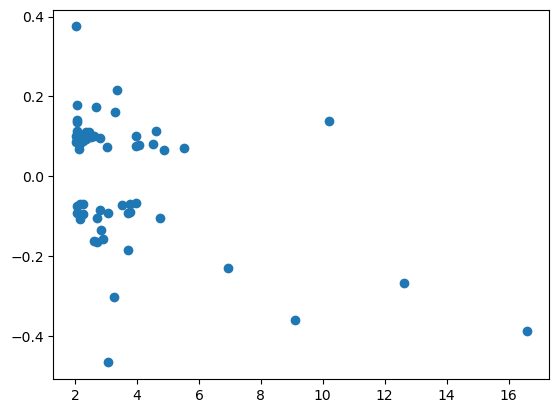

In [131]:
# add all true to df_final
df_new_true = df_new.loc[df_new['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_new_true])
plt.scatter(df_new_true['delta_Thermal_Shift'], df_new_true['delta_Spectral_Shift'])
df_final

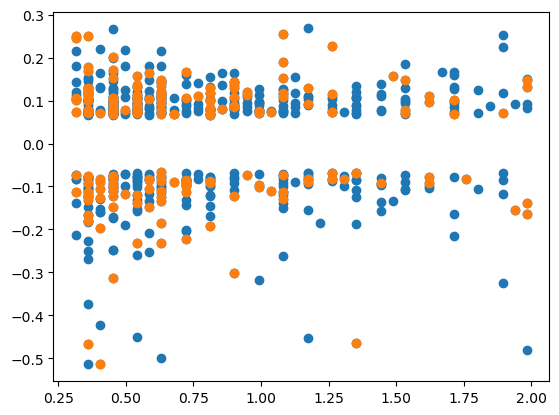

In [132]:
df_new_false = df_new.loc[~df_new['delta_TS_greater_2']]
df_subset = df_new_false.sample(n=193, random_state=100)
plt.scatter(df_new_false['delta_Thermal_Shift'], df_new_false['delta_Spectral_Shift'])
plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

In [133]:
df_final = pd.concat([df_final, df_subset])
df_final

,level_0,index,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_number,protein,hit_group,delta_TS_greater_2
0,0,2334,CSCS00028205893,2.0742,0.103874,PAH-WT,CSCS00028205893_WT,CSCS00028205893,1612.0,WT,S/WS/WN,True
5,5,2457,CSCS00133070215,2.3447,0.157605,PAH-WT,CSCS00133070215_WT,CSCS00133070215,1867.0,WT,S/WS/WN,True
15,16,2953,CSCS00025950759,3.2465,0.185692,PAH-WT,CSCS00025950759_WT,CSCS00025950759,2194.0,WT,S/WS/WN,True
16,17,5644,CSCS00027319139,2.8407,0.074163,PAH-WT,CSCS00027319139_WT,CSCS00027319139,2784.0,WT,S/WS/WN,True
25,27,6032,CSCS00027049410,2.7956,0.154890,PAH-WT,CSCS00027049410_WT,CSCS00027049410,3599.0,WT,S/WS/WN,True
...,...,...,...,...,...,...,...,...,...,...,...,...
589,977,33635,CSCS00027320057,0.7214,-0.111677,PAH-WT,CSCS00027320057_WT,CSCS00027320057,2052.0,WT,S/WS/WN,False
592,984,33809,CSCS00026427941,0.4058,0.072079,PAH-WT,CSCS00026427941_WT,CSCS00026427941,1453.0,WT,S/WS/WN,False
281,378,10358,CSCS00102898051,0.9018,0.142221,PAH-WT,CSCS00102898051_WT,CSCS00102898051,3488.0,WT,S/WS/WN,False
216,286,5943,CSCS00133086002,0.3607,-0.132421,PAH-WT,CSCS00133086002_WT,CSCS00133086002,3270.0,WT,S/WS/WN,False


In [134]:
print(df_merged.shape)
df_merged = df_merged.loc[~df_merged['cluster_number'].isin(df_final['cluster_number'])]
print(df_merged.shape)

(68691, 10)
(65187, 10)


In [136]:
i = 'S/WS/WN'

id_wt = set(df_merged.loc[(df_merged['protein'] == 'WT') & (df_merged['hit_group'] == i), 'ID'])
id_i65t = set(df_merged.loc[(df_merged['protein'] == 'I65T') & (df_merged['hit_group'] == i), 'ID'])

ids = {
            'both'    : id_wt.intersection(id_i65t),
            'WT_exc'   : id_wt - id_i65t,
            'I65T_exc' : id_i65t - id_wt
        }

df_new = df_merged.loc[((df_merged['ID'].isin(ids['I65T_exc'])) & (df_merged['hit_group'] == i) & (df_merged['protein'] == 'I65T'))].reset_index()
df_new = df_new.drop_duplicates(subset='cluster_number', keep='first').reset_index()
df_new['delta_TS_greater_2'].value_counts().sort_values()

delta_TS_greater_2
True      83
False    712
Name: count, dtype: int64

,level_0,index,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_number,protein,hit_group,delta_TS_greater_2
0,0,2334,CSCS00028205893,2.0742,0.103874,PAH-WT,CSCS00028205893_WT,CSCS00028205893,1612.0,WT,S/WS/WN,True
5,5,2457,CSCS00133070215,2.3447,0.157605,PAH-WT,CSCS00133070215_WT,CSCS00133070215,1867.0,WT,S/WS/WN,True
15,16,2953,CSCS00025950759,3.2465,0.185692,PAH-WT,CSCS00025950759_WT,CSCS00025950759,2194.0,WT,S/WS/WN,True
16,17,5644,CSCS00027319139,2.8407,0.074163,PAH-WT,CSCS00027319139_WT,CSCS00027319139,2784.0,WT,S/WS/WN,True
25,27,6032,CSCS00027049410,2.7956,0.154890,PAH-WT,CSCS00027049410_WT,CSCS00027049410,3599.0,WT,S/WS/WN,True
...,...,...,...,...,...,...,...,...,...,...,...,...
772,1618,72263,CSCS00026300424,2.0741,0.101622,PAH-I65T,CSCS00026300424_I65T,CSCS00026300424,2304.0,I65T,S/WS/WN,True
781,1642,72883,CSCS00046221618,8.8377,-0.064809,PAH-I65T,CSCS00046221618_I65T,CSCS00046221618,1982.0,I65T,S/WS/WN,True
782,1645,73008,CSCS00027006601,3.6974,0.051977,PAH-I65T,CSCS00027006601_I65T,CSCS00027006601,3710.0,I65T,S/WS/WN,True
783,1649,73131,CSCS00133077456,2.2545,-0.090530,PAH-I65T,CSCS00133077456_I65T,CSCS00133077456,871.0,I65T,S/WS/WN,True


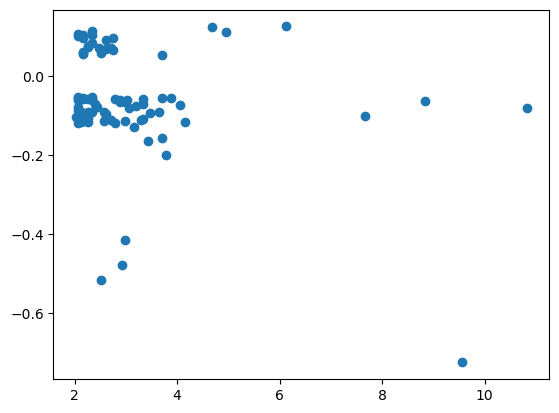

In [138]:
# add all true to df_final
df_new_true = df_new.loc[df_new['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_new_true])
plt.scatter(df_new_true['delta_Thermal_Shift'], df_new_true['delta_Spectral_Shift'])
df_final

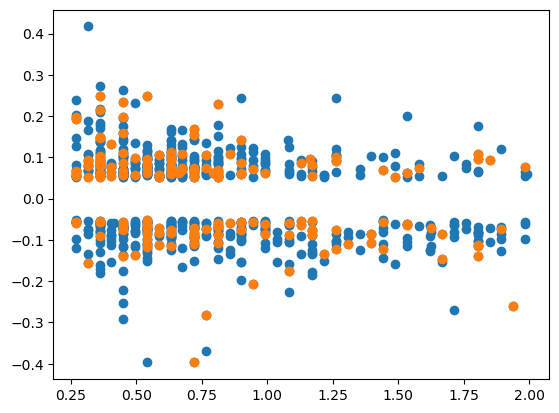

In [139]:
df_new_false = df_new.loc[~df_new['delta_TS_greater_2']]
df_subset = df_new_false.sample(n=167, random_state=100)
plt.scatter(df_new_false['delta_Thermal_Shift'], df_new_false['delta_Spectral_Shift'])
plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

In [140]:
df_final = pd.concat([df_final, df_subset])
df_final

,level_0,index,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_number,protein,hit_group,delta_TS_greater_2
0,0,2334,CSCS00028205893,2.0742,0.103874,PAH-WT,CSCS00028205893_WT,CSCS00028205893,1612.0,WT,S/WS/WN,True
5,5,2457,CSCS00133070215,2.3447,0.157605,PAH-WT,CSCS00133070215_WT,CSCS00133070215,1867.0,WT,S/WS/WN,True
15,16,2953,CSCS00025950759,3.2465,0.185692,PAH-WT,CSCS00025950759_WT,CSCS00025950759,2194.0,WT,S/WS/WN,True
16,17,5644,CSCS00027319139,2.8407,0.074163,PAH-WT,CSCS00027319139_WT,CSCS00027319139,2784.0,WT,S/WS/WN,True
25,27,6032,CSCS00027049410,2.7956,0.154890,PAH-WT,CSCS00027049410_WT,CSCS00027049410,3599.0,WT,S/WS/WN,True
...,...,...,...,...,...,...,...,...,...,...,...,...
752,1567,70924,CSCS00026102997,0.3608,-0.056359,PAH-I65T,CSCS00026102997_I65T,CSCS00026102997,3493.0,I65T,S/WS/WN,False
510,976,55454,CSCS00027999096,0.9018,-0.075215,PAH-I65T,CSCS00027999096_I65T,CSCS00027999096,3986.0,I65T,S/WS/WN,False
226,422,43097,CSCS00102901493,0.9469,-0.056199,PAH-I65T,CSCS00102901493_I65T,CSCS00102901493,3410.0,I65T,S/WS/WN,False
214,400,42722,CSCS00026533456,1.3978,-0.108413,PAH-I65T,CSCS00026533456_I65T,CSCS00026533456,1123.0,I65T,S/WS/WN,False


In [141]:
print(df_merged.shape)
df_merged = df_merged.loc[~df_merged['cluster_number'].isin(df_final['cluster_number'])]
print(df_merged.shape)

(65187, 10)
(61865, 10)


In [ ]:
# change protein name to both for both